# 02 · K-Nearest Neighbors

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter
from scipy.cluster.hierarchy import leaves_list, linkage

from comp472_project.config import FIGURES_DIR, RESULTS_DIR, SENTIMENT_LABELS, TASKS, seed_everything
from comp472_project.data import load_split, load_test, load_train
from comp472_project.evaluation import confusion_matrix, evaluate, most_confused_pairs, per_class_accuracy
from comp472_project.models import KNNClassifier
from comp472_project.preprocessing import Standardizer, SqrtTransform

seed_everything()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 3)

# Chart style: the same colours and settings as the EDA notebook.
INK, INK2, AXIS, GRID, SURFACE = "#0b0b0b", "#52514e", "#c3c2b7", "#e1e0d9", "#fcfcfb"
IMAGE_COLOR = "#2a78d6"
BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False,
})


def save(fig, name):
    fig.savefig(FIGURES_DIR / f"knn_{name}.png", dpi=200, bbox_inches="tight")

# Images

In [2]:
# Try k-NN settings on the fixed train/validation split from data/splits/image.csv
# (16,000 train rows, 4,000 validation rows), the same split every model uses.
image_data = load_split("image")

# k: spread out, roughly doubling each step, so we see the whole trend.
K_VALUES = [1, 3, 5, 10, 20, 50, 100, 200]

# Feature scaling. Each entry makes a fresh list of transforms. evaluate() fits
# them on the train split only, then applies them to the validation split.
IMAGE_SCALINGS = {
    "none": lambda: [],
    "standard": lambda: [Standardizer()],
    "sqrt": lambda: [SqrtTransform()],
    "sqrt+standard": lambda: [SqrtTransform(), Standardizer()],
}

# Distance: euclidean and cosine in the sweep.
# - On the original features every row has length 1, so the two rank neighbours
#   the same way. After standardizing or taking the square root, row lengths
#   differ and the two distances can give different results.
# - manhattan: about 100x slower (no matrix-multiplication shortcut), so it
#   gets a single run further down, with the best settings from the sweep.

image_rows = []
for scaling, make_transforms in IMAGE_SCALINGS.items():
    for weighted in [False, True]:
        for metric in ["euclidean", "cosine"]:
            for k in K_VALUES:
                model = KNNClassifier(k=k, metric=metric, weighted=weighted)
                # train_metrics=False: predicting all 16,000 training rows is slow,
                # and each training row finds itself as its own nearest neighbour,
                # so training accuracy tells us little for k-NN.
                metrics, _ = evaluate(model, image_data, transforms=make_transforms(), train_metrics=False)
                image_rows.append(
                    {"metric": metric, "k": k, "weighted": weighted, "scaling": scaling, **metrics}
                )
                print(f"{metric:9s} scaling={scaling:13s} weighted={weighted!s:5s} k={k:3d}  val_acc={metrics['val_acc']:.3f}")

# Manhattan: one run (about 2 minutes) with the best settings from the sweep.
best = max(image_rows, key=lambda r: r["val_acc"])
model = KNNClassifier(k=best["k"], metric="manhattan", weighted=best["weighted"])
metrics, _ = evaluate(model, image_data, transforms=IMAGE_SCALINGS[best["scaling"]](), train_metrics=False)
image_rows.append(
    {"metric": "manhattan", "k": best["k"], "weighted": best["weighted"], "scaling": best["scaling"], **metrics}
)

print(
    f"\nBest {best['metric']}, k={best['k']}, weighted={best['weighted']}, scaling={best['scaling']}"
    f" -> val_acc={best['val_acc']:.3f}"
)
print(f"Manhattan, same settings -> val_acc={metrics['val_acc']:.3f}  ({metrics['predict_time_s']:.0f}s)")

# Save every run. Writing the whole table (instead of appending) means
# re-running this cell replaces the file rather than duplicating rows.
image_results = pd.DataFrame(image_rows)
image_results.to_csv(RESULTS_DIR / "knn_image.csv", index=False)

# Validation accuracy of the sweep runs: one row per k,
# one column per (distance, scaling, weighted) combination.
image_results[image_results["metric"] != "manhattan"].pivot_table(
    index="k", columns=["metric", "scaling", "weighted"], values="val_acc"
)

euclidean scaling=none          weighted=False k=  1  val_acc=0.519


euclidean scaling=none          weighted=False k=  3  val_acc=0.510


euclidean scaling=none          weighted=False k=  5  val_acc=0.492


euclidean scaling=none          weighted=False k= 10  val_acc=0.444


euclidean scaling=none          weighted=False k= 20  val_acc=0.399


euclidean scaling=none          weighted=False k= 50  val_acc=0.335


... (120 outputs left out)

cosine    scaling=sqrt+standard weighted=True  k=100  val_acc=0.325


cosine    scaling=sqrt+standard weighted=True  k=200  val_acc=0.274



Best cosine, k=1, weighted=False, scaling=sqrt+standard -> val_acc=0.565
Manhattan, same settings -> val_acc=0.302  (104s)


metric   cosine                                                            \
scaling    none          sqrt        sqrt+standard        standard          
weighted  False  True   False  True          False  True     False  True    
k                                                                           
1         0.519  0.519  0.563  0.563         0.565  0.565    0.533  0.533   
3         0.511  0.511  0.555  0.555         0.557  0.557    0.528  0.529   
5         0.492  0.492  0.534  0.535         0.535  0.537    0.501  0.503   
10        0.444  0.448  0.490  0.491         0.490  0.494    0.455  0.459   
20        0.399  0.406  0.447  0.452         0.445  0.448    0.425  0.427   
50        0.335  0.344  0.369  0.378         0.376  0.384    0.361  0.370   
100       0.295  0.307  0.321  0.325         0.316  0.325    0.314  0.320   
200       0.254  0.266  0.267  0.273         0.265  0.274    0.265  0.276   

metric   euclidean                                                            
scaling       none          sqrt        sqrt+standard        standard         
weighted     False  True   False  True          False  True     False  True   
k                                                                             
1            0.519  0.519  0.432  0.432         0.378  0.378    0.430  0.430  
3            0.510  0.511  0.409  0.409         0.325  0.325    0.415  0.415  
5            0.492  0.492  0.370  0.372         0.283  0.284    0.381  0.384  
10           0.444  0.446  0.313  0.313         0.249  0.247    0.328  0.331  
20           0.399  0.400  0.262  0.263         0.213  0.214    0.285  0.287  
50           0.335  0.336  0.202  0.202         0.171  0.173    0.227  0.228  
100          0.295  0.296  0.167  0.168         0.145  0.145    0.186  0.187  
200          0.255  0.256  0.147  0.148         0.127  0.127    0.169  0.167

## Error analysis: the best image setting

The cell below re-runs the best setting from the sweep and saves its prediction for every validation image to `results/predictions/knn_image_val.csv` (`id`, `true`, `pred`), so a later notebook can compare k-NN's mistakes with the other models'. The best setting is looked up from the sweep results each time, so re-running the notebook always saves the current best.

In [3]:
# The row of the sweep table with the highest validation accuracy.
# If two settings tie, the one that comes first in the table wins.
best_image = image_results.loc[image_results["val_acc"].idxmax()]
best_image_model = KNNClassifier(
    k=int(best_image["k"]), metric=best_image["metric"], weighted=bool(best_image["weighted"])
)
# This time we keep the second thing evaluate() returns: the prediction for each validation image.
_, image_val_pred = evaluate(
    best_image_model, image_data, transforms=IMAGE_SCALINGS[best_image["scaling"]](), train_metrics=False
)

# One row per validation image. Saving the id with each prediction lets a later notebook
# line up k-NN's answers with other models' answers image by image.
PREDICTIONS_DIR = RESULTS_DIR / "predictions"
PREDICTIONS_DIR.mkdir(parents=True, exist_ok=True)
pd.DataFrame({"id": image_data.ids_val, "true": image_data.y_val, "pred": image_val_pred}).to_csv(
    PREDICTIONS_DIR / "knn_image_val.csv", index=False
)

image_correct = image_val_pred == image_data.y_val  # True where k-NN got the image right
print(
    f"best setting: metric={best_image['metric']}, k={best_image['k']}, "
    f"weighted={best_image['weighted']}, scaling={best_image['scaling']}"
)
print(f"validation accuracy: {image_correct.mean():.3f}  "
      f"({(~image_correct).sum()} of {len(image_correct)} images wrong)")
print(f"saved to {PREDICTIONS_DIR / 'knn_image_val.csv'}")

best setting: metric=cosine, k=1, weighted=False, scaling=sqrt+standard
validation accuracy: 0.565  (1740 of 4000 images wrong)
saved to /home/kc/comp472_project/results/predictions/knn_image_val.csv


### 1. Accuracy of each class

Every class has 80 validation images, so the overall accuracy is the average of the 50 per-class accuracies and can hide classes that are much easier or harder than the rest.

hardest classes: 22 (35%), 7 (42%), 26 (42%), 41 (44%), 29 (46%)
easiest classes: 48 (84%), 18 (78%), 13 (78%), 46 (76%), 5 (74%)


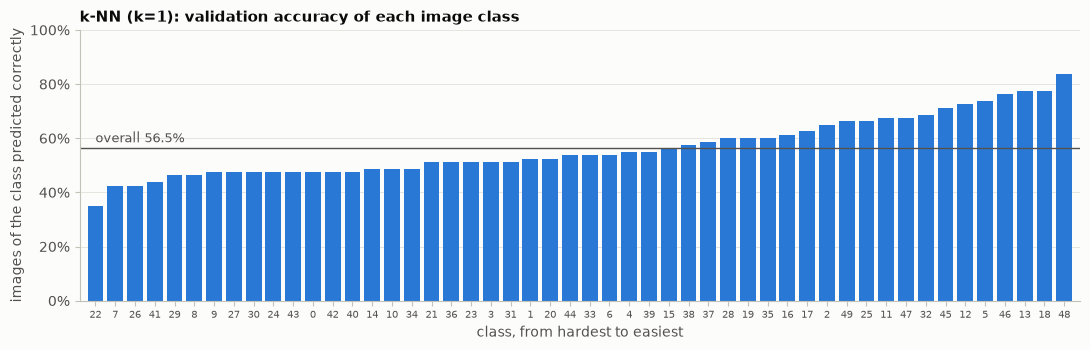

In [4]:
# image_cm[i, j] = number of validation images whose true class is i and that k-NN predicted as j.
image_cm = confusion_matrix(image_data.y_val, image_val_pred, n_classes=50)
image_class_acc = per_class_accuracy(image_cm)  # for each class: images right / 80

by_difficulty = np.argsort(image_class_acc)  # class numbers, hardest first
print("hardest classes:", ", ".join(f"{c} ({image_class_acc[c]:.0%})" for c in by_difficulty[:5]))
print("easiest classes:", ", ".join(f"{c} ({image_class_acc[c]:.0%})" for c in by_difficulty[::-1][:5]))

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(np.arange(50), image_class_acc[by_difficulty], width=0.8, color=IMAGE_COLOR)
ax.axhline(image_correct.mean(), color=INK2, lw=1)
ax.text(0, image_correct.mean() + 0.02, f"overall {image_correct.mean():.1%}", color=INK2, fontsize=9)
ax.set_xticks(range(50), by_difficulty, fontsize=7)
ax.set_xlim(-0.8, 49.8)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(axis="x", visible=False)
ax.set(title=f"k-NN (k={best_image['k']}): validation accuracy of each image class",
       xlabel="class, from hardest to easiest", ylabel="images of the class predicted correctly")
fig.tight_layout()
save(fig, "image_per_class")

### 2. Confusion matrix

The diagonal is left blank, otherwise the correct answers would take up the whole colour scale. The classes are reordered by hierarchical clustering of their average feature vectors (as in EDA §6c), so classes that are similar on average sit next to each other. The averages use the original features, before any square root or standardizing. If k-NN mostly confuses classes that look alike on average, the dark cells will gather close to the diagonal.

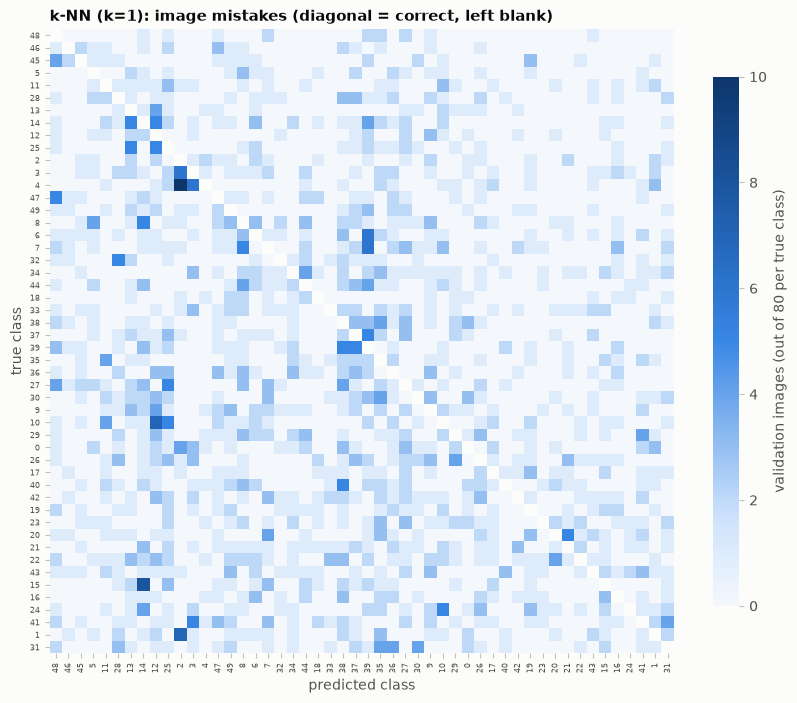

In [5]:
# Average feature vector of each class (train split only), scaled to length 1 so that
# a dot product between two of them is their cosine similarity (1 = same direction).
image_class_means = np.stack([image_data.X_train[image_data.y_train == c].mean(axis=0) for c in range(50)])
unit_means = image_class_means / np.linalg.norm(image_class_means, axis=1, keepdims=True)
image_class_sim = unit_means @ unit_means.T  # image_class_sim[a, b] = similarity of classes a and b

# Hierarchical clustering repeatedly joins the two most similar groups of classes. Reading off
# the order it joined them in puts similar classes next to each other. Only used to order the plot.
plot_order = leaves_list(linkage(unit_means, method="average", metric="cosine"))

mistakes = image_cm.astype(float)
np.fill_diagonal(mistakes, np.nan)  # blank out the correct answers

fig, ax = plt.subplots(figsize=(8.5, 7.5))
im = ax.imshow(mistakes[np.ix_(plot_order, plot_order)], cmap=BLUES, vmin=0)
ax.grid(False)
ax.set_xticks(range(50), plot_order, fontsize=6, rotation=90)
ax.set_yticks(range(50), plot_order, fontsize=6)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set(title=f"k-NN (k={best_image['k']}): image mistakes (diagonal = correct, left blank)",
       xlabel="predicted class", ylabel="true class")
cb = fig.colorbar(im, ax=ax, shrink=0.75)
cb.outline.set_visible(False)
cb.set_label("validation images (out of 80 per true class)", color=INK2)
fig.tight_layout()
save(fig, "image_mistakes")

### 3. Most-confused pairs

The ten largest off-diagonal cells (`count` is out of the 80 images of class `true`). To check whether these mix-ups happen because the two classes look alike *on average*, two more columns compare the classes' average feature vectors (original features):
- `similarity`: their cosine similarity.
- `more similar than`: the share of all 1,225 pairs of classes that are *less* similar than this pair. 90% means only 10% of class pairs are more alike.

In [6]:
pairs = most_confused_pairs(image_cm, top=10)
pairs["similarity"] = image_class_sim[pairs["true"], pairs["pred"]]

# Similarity of every pair of different classes (each pair once).
all_pair_sims = image_class_sim[np.triu_indices(50, k=1)]
pairs["more similar than"] = [(all_pair_sims < s).mean() for s in pairs["similarity"]]

print(f"similarity over all {len(all_pair_sims)} pairs of classes: "
      f"median {np.median(all_pair_sims):.2f}, range {all_pair_sims.min():.2f} to {all_pair_sims.max():.2f}")
pairs.style.format({"similarity": "{:.3f}", "more similar than": "{:.0%}"}).hide(axis="index")

similarity over all 1225 pairs of classes: median 0.89, range 0.60 to 0.97


true,pred,count,similarity,more similar than
4,2,10,0.938,88%
15,14,8,0.875,43%
10,12,7,0.932,84%
1,2,7,0.860,35%
3,2,6,0.942,92%
7,39,6,0.925,78%
4,3,6,0.946,95%
6,39,6,0.920,73%
25,13,5,0.869,40%
27,25,5,0.889,50%


### 4. Dense vs. sparse images

The EDA notebook (§2) found two groups of images. "Sparse" images have a non-zero value in about 50
of their 500 features, "dense" images in about 115. The EDA splits them at 80 non-zero features,
which falls in the gap between the two groups. Both groups contain every class, so the group says
something about how the picture was taken, not about which object it shows. Does k-NN do worse on
one of the two groups?

In [7]:
# Same rule as the EDA notebook: an image is "dense" if more than 80 of its 500 features are non-zero.
val_dense = (image_data.X_val > 0).sum(axis=1) > 80

pd.DataFrame(
    {
        "validation images": [val_dense.sum(), (~val_dense).sum()],
        "k-NN accuracy": [image_correct[val_dense].mean(), image_correct[~val_dense].mean()],
    },
    index=pd.Index(["dense (more than 80 non-zero)", "sparse (80 or fewer non-zero)"], name="group"),
)

,validation images,k-NN accuracy
group,,
dense (more than 80 non-zero),1541,0.623
sparse (80 or fewer non-zero),2459,0.529


# Sentiment

In [8]:
# Try k-NN settings on the fixed train/validation split from data/splits/sentiment.csv
# (9,600 train rows, 2,400 validation rows), the same split every model uses.
sentiment_data = load_split("sentiment")

# k: spread out, roughly doubling each step, so we see the whole trend.
K_VALUES = [1, 3, 5, 10, 20, 50, 100, 200]

# Feature scaling. Each entry makes a fresh list of transforms. evaluate() fits
# them on the train split only, then applies them to the validation split.
# We do not include L2Normalization because cosine already covers that,
# and we can't sqaure-root the features because more than half of them are negative
SENTIMENT_SCALINGS = {
    "none": lambda: [],
    "standard": lambda: [Standardizer()]
}

# Distance: euclidean and cosine in the sweep.
# - manhattan: about 100x slower (no matrix-multiplication shortcut), so it
#   gets a single run further down, with the best settings from the sweep.

sentiment_rows = []
for scaling, make_transforms in SENTIMENT_SCALINGS.items():
    for weighted in [False, True]:
        for metric in ["euclidean", "cosine"]:
            for k in K_VALUES:
                model = KNNClassifier(k=k, metric=metric, weighted=weighted)
                # train_metrics=False: predicting all 9,600 training rows is slow,
                # and each training row finds itself as its own nearest neighbour,
                # so training accuracy tells us little for k-NN.
                metrics, _ = evaluate(model, sentiment_data, transforms=make_transforms(), train_metrics=False)
                sentiment_rows.append(
                    {"metric": metric, "k": k, "weighted": weighted, "scaling": scaling, **metrics}
                )
                print(f"{metric:9s} scaling={scaling:8s} weighted={weighted!s:5s} k={k:3d}  val_acc={metrics['val_acc']:.3f}")

# Manhattan: one run (about 1 minute) with the k, weighting and scaling of the best sweep run.
best = max(sentiment_rows, key=lambda r: r["val_acc"])
model = KNNClassifier(k=best["k"], metric="manhattan", weighted=best["weighted"])
metrics, _ = evaluate(model, sentiment_data, transforms=SENTIMENT_SCALINGS[best["scaling"]](), train_metrics=False)
sentiment_rows.append(
    {"metric": "manhattan", "k": best["k"], "weighted": best["weighted"], "scaling": best["scaling"], **metrics}
)

print(
    f"\nBest: {best['metric']}, k={best['k']}, weighted={best['weighted']}, scaling={best['scaling']}"
    f" -> val_acc={best['val_acc']:.3f}"
)
print(f"Manhattan, same settings -> val_acc={metrics['val_acc']:.3f}  ({metrics['predict_time_s']:.0f}s)")

# Save every run. Writing the whole table (instead of appending) means
# re-running this cell replaces the file rather than duplicating rows.
sentiment_results = pd.DataFrame(sentiment_rows)
sentiment_results.to_csv(RESULTS_DIR / "knn_sentiment.csv", index=False)

euclidean scaling=none     weighted=False k=  1  val_acc=0.488


euclidean scaling=none     weighted=False k=  3  val_acc=0.517


euclidean scaling=none     weighted=False k=  5  val_acc=0.541


euclidean scaling=none     weighted=False k= 10  val_acc=0.550


euclidean scaling=none     weighted=False k= 20  val_acc=0.571


euclidean scaling=none     weighted=False k= 50  val_acc=0.582


... (55 outputs left out)

cosine    scaling=standard weighted=True  k= 50  val_acc=0.589


cosine    scaling=standard weighted=True  k=100  val_acc=0.586


cosine    scaling=standard weighted=True  k=200  val_acc=0.580



Best: cosine, k=50, weighted=True, scaling=none -> val_acc=0.590
Manhattan, same settings -> val_acc=0.584  (55s)


In [9]:
# Validation accuracy of every sweep run, in one table:
# one row per k, one column per (distance, scaling, voting) combination.
# Manhattan was run only once, so it is reported in the caption
# instead of as a column that would be empty except for one cell.
sweep = sentiment_results[sentiment_results["metric"] != "manhattan"]
manhattan_run = sentiment_results[sentiment_results["metric"] == "manhattan"].iloc[0]
best_run = sweep.loc[sweep["val_acc"].idxmax()]

SCALING_NAMES = {"none": "raw", "standard": "standardized"}
VOTING_NAMES = {False: "plain vote", True: "weighted vote"}


def describe(run):
    return f"k={run['k']}, {VOTING_NAMES[run['weighted']]}, {SCALING_NAMES[run['scaling']]}"


sentiment_table = (
    sweep.assign(
        distance=sweep["metric"],
        scaling=sweep["scaling"].map(SCALING_NAMES),
        voting=sweep["weighted"].map(VOTING_NAMES),
    )
    .pivot_table(index="k", columns=["distance", "scaling", "voting"], values="val_acc")
    .reindex(columns=["euclidean", "cosine"], level="distance")  # euclidean first, as in the image table
)

# A thin line before the first column of each distance, to separate the two blocks.
block_starts = [col for col in sentiment_table.columns if col[1:] == ("raw", "plain vote")][1:]
n_val = len(sentiment_data.y_val)

# Only the lighter half of the blue scale, so the text stays dark and readable
# and the outline around the best cell stays visible.
LIGHT_BLUES = LinearSegmentedColormap.from_list("light_blues", BLUES(np.linspace(0, 0.5, 8)))

(
    sentiment_table.style
    .format("{:.1%}")
    .background_gradient(cmap=LIGHT_BLUES, axis=None, text_color_threshold=0)  # darker = higher accuracy; text always dark
    .highlight_max(axis=0, props="font-weight: bold;")                # best k in each column
    .highlight_max(axis=None, props=f"outline: 2px solid {INK}; outline-offset: -2px;")  # best overall
    .set_properties(subset=block_starts, **{"border-left": f"2px solid {AXIS}"})
    .set_table_styles([
        {"selector": "caption", "props": f"caption-side: top; text-align: left; color: {INK2}; padding-bottom: 8px;"},
        {"selector": "th", "props": "text-align: center; font-weight: normal; padding: 3px 10px;"},
        {"selector": "th.col_heading.level0", "props": "font-weight: bold;"},
        {"selector": "th.row_heading", "props": "text-align: right; font-weight: bold;"},
        {"selector": "td", "props": "text-align: right; padding: 4px 10px;"},
    ])
    .set_caption(
        f"<b style='color:{INK}'>Sentiment k-NN: validation accuracy ({n_val:,} texts)</b><br>"
        "Darker = higher accuracy. <b>Bold</b> = best k in each column. Boxed = best overall: "
        f"{best_run['metric']}, {describe(best_run)} ({best_run['val_acc']:.1%}).<br>"
        f"Manhattan, run once with the best run's settings ({describe(manhattan_run)}): "
        f"{manhattan_run['val_acc']:.1%}, in {manhattan_run['predict_time_s']:.0f} s "
        f"(euclidean and cosine take about 1 s).<br>"
        "With this many texts, differences smaller than about 2 points can come from which texts "
        "happen to be in the validation split."
    )
)

## Error analysis: the best sentiment setting

Same procedure as for images. The project brief asks specifically whether Neutral is harder to identify than Negative or Positive. Predictions are saved to `results/predictions/knn_sentiment_val.csv` (`id`, `true`, `pred`).

In [10]:
# The row of the sweep table with the highest validation accuracy (ties: the first one in the table).
best_sentiment = sentiment_results.loc[sentiment_results["val_acc"].idxmax()]
best_sentiment_model = KNNClassifier(
    k=int(best_sentiment["k"]), metric=best_sentiment["metric"], weighted=bool(best_sentiment["weighted"])
)
# Keep the list of transforms: evaluate() fits them on the train split, and parts 3 and 6 below
# reuse them to scale texts exactly the way the model saw them.
sentiment_transforms = SENTIMENT_SCALINGS[best_sentiment["scaling"]]()
_, sentiment_val_pred = evaluate(
    best_sentiment_model, sentiment_data, transforms=sentiment_transforms, train_metrics=False
)


def scale_sentiment(X):
    """Scale texts with the best setting's transforms (already fitted on the train split)."""
    for t in sentiment_transforms:
        X = t.transform(X)
    return X


pd.DataFrame({"id": sentiment_data.ids_val, "true": sentiment_data.y_val, "pred": sentiment_val_pred}).to_csv(
    PREDICTIONS_DIR / "knn_sentiment_val.csv", index=False
)

sentiment_correct = sentiment_val_pred == sentiment_data.y_val  # True where k-NN got the text right
print(
    f"best setting: metric={best_sentiment['metric']}, k={best_sentiment['k']}, "
    f"weighted={best_sentiment['weighted']}, scaling={best_sentiment['scaling']}"
)
print(f"validation accuracy: {sentiment_correct.mean():.3f}  "
      f"({(~sentiment_correct).sum()} of {len(sentiment_correct)} texts wrong)")
print(f"saved to {PREDICTIONS_DIR / 'knn_sentiment_val.csv'}")

best setting: metric=cosine, k=50, weighted=True, scaling=none
validation accuracy: 0.590  (985 of 2400 texts wrong)
saved to /home/kc/comp472_project/results/predictions/knn_sentiment_val.csv


### 1. Accuracy of each sentiment, and what each one is mistaken for

The confusion matrix (800 validation texts per class), with two extra parts:
- `accuracy of the class`: the share of that row's 800 texts that k-NN got right.
- `share of all predictions`: how often k-NN gives each answer. The validation split has exactly one third of each class, so a model with no preference for any class would be near 33% in each column.

In [11]:
SENTIMENT_NAMES = [SENTIMENT_LABELS[c] for c in range(3)]  # Negative, Neutral, Positive


def predicted_shares(pred):
    """Share of the predictions that went to each sentiment class."""
    return np.bincount(pred, minlength=3) / len(pred)


# sentiment_cm[i, j] = number of validation texts whose true class is i and that k-NN predicted as j.
sentiment_cm = confusion_matrix(sentiment_data.y_val, sentiment_val_pred, n_classes=3)
sentiment_class_acc = per_class_accuracy(sentiment_cm)

cm_table = pd.DataFrame(
    sentiment_cm.astype(float),  # float, so the row of shares below fits in the same columns
    index=pd.Index(SENTIMENT_NAMES, name="true class"),
    columns=pd.Index(SENTIMENT_NAMES, name="predicted class"),
)
cm_table["accuracy of the class"] = sentiment_class_acc
cm_table.loc["share of all predictions"] = [*predicted_shares(sentiment_val_pred), np.nan]

(
    cm_table.style
    .format("{:.0f}", subset=pd.IndexSlice[SENTIMENT_NAMES, SENTIMENT_NAMES])
    .format("{:.0%}", subset=pd.IndexSlice[:, "accuracy of the class"], na_rep="")
    .format("{:.0%}", subset=pd.IndexSlice["share of all predictions", :], na_rep="")
)

predicted class,Negative,Neutral,Positive,accuracy of the class
true class,,,,
Negative,603,78,119,75%
Neutral,252,270,278,34%
Positive,167,91,542,68%
share of all predictions,43%,18%,39%,


**Neutral is by far the hardest class.** k-NN gets 75% of Negative texts and 68% of Positive texts right,
but only 34% of Neutral texts. That's about what guessing at random among 3 classes would give.
Neutral's mistakes split almost evenly between Negative (252) and Positive (278). Mixing up the two
*opposite* sentiments is less common (119 Negative texts called Positive, 167 the other way round).

k-NN also **rarely answers Neutral**: only 18% of its predictions, although a third of the texts are
Neutral. The missing Neutral answers go to Negative (43%) and Positive (39%). Parts 3 to 5 look at why.

### 2. Is this a bug in our k-NN?

No. `tests/test_models.py::test_knn_matches_sklearn` compares our k-NN with scikit-learn's on made-up data where the classes overlap heavily, so many votes are close. The test
covers all three distances, with plain and weighted votes. Both give exactly the same prediction for every
test row. To confirm the test can catch real mistakes, we temporarily broke our k-NN in two ways: weighting
votes by distance instead of 1 / distance, and using the farthest neighbours instead of the nearest. The
broken versions disagreed with scikit-learn on 41 and 149 of the 200 rows.

scikit-learn is used **only in that test**, to check our code. It makes none of the predictions in this
notebook or in the submission. Run the test with `uv run pytest tests/test_models.py -k sklearn`.

### 3. Why k-NN rarely predicts Neutral

The best setting votes among the 50 nearest training texts. The table below finds those neighbours for every validation text, using the same distance as the model over all 768 features, and shows the average share of neighbours from each class, for each true class.

In [12]:
best_k = int(best_sentiment["k"])
MAX_K = max(K_VALUES)  # part 4 below looks at every k up to this

# Distance from every validation text to every training text (2,400 x 9,600), using the
# model's own distance function, then the training rows sorted closest first.
sentiment_dist = best_sentiment_model._distances(scale_sentiment(sentiment_data.X_val))
nearest_rows = np.argsort(sentiment_dist, axis=1)[:, :MAX_K]
nearest_labels = sentiment_data.y_train[nearest_rows]  # nearest_labels[i, j] = class of the (j+1)-th closest training text
del sentiment_dist  # about 180 MB, no longer needed

neighbour_mix = pd.DataFrame(
    [[(nearest_labels[sentiment_data.y_val == true, :best_k] == c).mean() for c in range(3)] for true in range(3)],
    index=pd.Index(SENTIMENT_NAMES, name="true class"),
    columns=pd.Index(SENTIMENT_NAMES, name=f"share of the {best_k} nearest training texts that are"),
)
neighbour_mix.style.format("{:.0%}")

share of the 50 nearest training texts that are,Negative,Neutral,Positive
true class,,,
Negative,51%,25%,24%
Neutral,30%,35%,34%
Positive,25%,26%,48%


- A **Negative** text's neighbours are about half Negative (51%). The other half splits between
  Neutral and Positive, so Negative usually wins the vote. **Positive** is similar (48%).
- A **Neutral** text's neighbours split almost evenly: 30% Negative, 35% Neutral, 34% Positive. With a
  near three-way tie, small random differences decide which class gets the most votes. So Neutral wins
  only about a third of the time, which matches its 34% accuracy in part 1.
- Neutral texts sit **between** the two other classes. EDA §6b found the same thing with the class
  averages: the average Neutral text lies between the average Negative and the average Positive text.

The EDA's 2-D picture of the sentiment texts (§6e) shows this overlap:

<img src="../results/figures/eda_sentiment_tsne.png" width="480">

That picture is a t-SNE projection. There are areas where Negative (red) or Positive
(blue) dots are more common, Neutral (gray) dots are scattered through all of them, and no area belongs
clearly to one class. With neighbourhoods this mixed, votes are close and many answers are wrong. That is why k-NN struggles here, most of all on Neutral.

Two limits on what the picture shows:
- It squeezes 768 features into 2 dimensions. Before running t-SNE, the EDA also standardized the
  features and reduced them to 50 dimensions with PCA. So the picture is a rough view and
  can hide separation that exists in the full data. The table above is the direct evidence: it measures
  the neighbours in the space k-NN actually uses.
- The overlap limits **every** method that uses these features, not just k-NN. What is specific to k-NN
  is how its vote treats a class that sits in the middle. Part 4 shows this, and part 5 compares k-NN
  with a different method.

### 4. A larger k makes Neutral worse

For each k from the sweep, the table shows:
- `own class among neighbours`: what share of a text's k nearest training texts belong to the text's own
  class (averaged over the validation texts of that class).
- `accuracy`: k-NN's accuracy on that class (same distance and voting as the best setting).
- `predicted Neutral`: the share of all answers that are Neutral (33% would match the true share).

In [13]:
k_rows = []
for k in K_VALUES:
    model = KNNClassifier(k=k, metric=best_sentiment["metric"], weighted=bool(best_sentiment["weighted"]))
    model.fit(scale_sentiment(sentiment_data.X_train), sentiment_data.y_train)
    pred = model.predict(scale_sentiment(sentiment_data.X_val))
    class_acc = per_class_accuracy(confusion_matrix(sentiment_data.y_val, pred, n_classes=3))
    row = {("", "k"): k}
    for c, name in enumerate(SENTIMENT_NAMES):
        row[("own class among neighbours", name)] = (nearest_labels[sentiment_data.y_val == c, :k] == c).mean()
    for c, name in enumerate(SENTIMENT_NAMES):
        row[("accuracy", name)] = class_acc[c]
    row[("accuracy", "overall")] = (pred == sentiment_data.y_val).mean()
    row[("", "predicted Neutral")] = predicted_shares(pred)[1]
    k_rows.append(row)

k_table = pd.DataFrame(k_rows).set_index(("", "k"))
k_table.index.name = "k"
k_table.style.format("{:.0%}")

,"('own class among neighbours', 'Negative')","('own class among neighbours', 'Neutral')","('own class among neighbours', 'Positive')","('accuracy', 'Negative')","('accuracy', 'Neutral')","('accuracy', 'Positive')","('accuracy', 'overall')","('', 'predicted Neutral')"
k,,,,,,,,
1,54%,40%,52%,54%,40%,52%,49%,30%
3,54%,41%,51%,59%,45%,55%,53%,30%
5,54%,39%,50%,61%,41%,58%,54%,28%
10,53%,38%,49%,68%,39%,62%,56%,24%
20,52%,36%,49%,71%,37%,64%,58%,22%
50,51%,35%,48%,75%,34%,68%,59%,18%
100,50%,34%,47%,76%,28%,68%,58%,16%
200,48%,33%,46%,76%,25%,71%,58%,13%


- **Neutral texts barely group together.** Even with k = 1, a Neutral text's single closest training text
  is Neutral only 40% of the time, against 54% for Negative and 52% for Positive. As k grows, the share of Neutral
  among its neighbours drops to 33% at k = 200. That's no more than Neutral's share of the whole
  training set.
- **A larger k averages more votes, so the result depends less on luck and more on which class has the
  most neighbours overall.** That helps a class that clearly has the most neighbours: Negative accuracy
  rises from 54% (k = 1) to 76% (k = 200). It hurts a class that is never clearly ahead: Neutral accuracy
  peaks at 45% (k = 3), then falls to 25% (k = 200), and k-NN predicts Neutral less and less often.
- **Overall accuracy peaks at k = 50.** Up to that point, the gains on Negative and Positive outweigh
  the losses on Neutral. So the best k is the best *trade*, not a k that is good for every class.

### 5. Is it k-NN, or would any method do this with these features?

To compare: the nearest-centroid baseline from EDA §6a, in our own code, with cosine distance (the same distance as our best k-NN).

In [14]:
def nearest_centroid(X_train, y_train, X):
    """Class whose average training vector points in the most similar direction (cosine) to each row of X."""
    centroids = np.stack([X_train[y_train == c].mean(axis=0) for c in range(3)])
    centroids /= np.linalg.norm(centroids, axis=1, keepdims=True)
    X_unit = X / np.linalg.norm(X, axis=1, keepdims=True)
    return (X_unit @ centroids.T).argmax(axis=1)


sentiment_X_train_scaled = scale_sentiment(sentiment_data.X_train)
centroid_val_pred = nearest_centroid(sentiment_X_train_scaled, sentiment_data.y_train,
                                     scale_sentiment(sentiment_data.X_val))
centroid_class_acc = per_class_accuracy(confusion_matrix(sentiment_data.y_val, centroid_val_pred, n_classes=3))

method_table = pd.DataFrame(
    {
        **{("accuracy", name): [sentiment_class_acc[c], centroid_class_acc[c]] for c, name in enumerate(SENTIMENT_NAMES)},
        ("accuracy", "overall"): [sentiment_correct.mean(), (centroid_val_pred == sentiment_data.y_val).mean()],
        **{("share of predictions", name): [predicted_shares(sentiment_val_pred)[c], predicted_shares(centroid_val_pred)[c]]
           for c, name in enumerate(SENTIMENT_NAMES)},
    },
    index=pd.Index([f"k-NN (k={best_k})", "nearest centroid"], name="method"),
)
method_table.style.format("{:.0%}")

Nearest centroid also finds Neutral hardest (45% accuracy). That comes from the features: Neutral texts
overlap with both other classes. But it predicts Neutral for 29% of texts, much closer to the true 33%
than k-NN's 18%. So **the features alone don't force a model to ignore Neutral. k-NN's vote makes it
worse.** k-NN gets the higher accuracy overall (59% vs. 57%), because it is better on Negative and
Positive and gives up Neutral to get there.

### 6. On the test set, k-NN predicts Neutral even less often

For a fair comparison between validation and test, both methods below are fitted on the **train split**
only. The only thing that changes between the two columns is the texts being classified.

In [15]:
_, sentiment_X_test = load_test("sentiment")
sentiment_X_test_scaled = scale_sentiment(sentiment_X_test)

shift_table = pd.DataFrame(
    {
        (f"k-NN (k={best_k})", "validation"): predicted_shares(sentiment_val_pred),
        (f"k-NN (k={best_k})", "test"): predicted_shares(best_sentiment_model.predict(sentiment_X_test_scaled)),
        ("nearest centroid", "validation"): predicted_shares(centroid_val_pred),
        ("nearest centroid", "test"): predicted_shares(
            nearest_centroid(sentiment_X_train_scaled, sentiment_data.y_train, sentiment_X_test_scaled)
        ),
    },
    index=pd.Index(SENTIMENT_NAMES, name="share of predictions"),
)
shift_table.style.format("{:.0%}")

On the test texts, **both** methods move the same way: more Negative answers (k-NN 43% → 57%, nearest
centroid 37% → 45%) and fewer of the others. Two very different methods making the same move means the
cause is in the **test texts**, not in k-NN. EDA §4 found this: the sentiment test texts look clearly
different from the training texts (train-vs-test AUC 0.87). The
difference is too large to be explained by a different mix of sentiments alone. k-NN again makes the
effect bigger: its Neutral answers fall from 18% to 9%, while nearest centroid's fall only from 29% to 26%.

We can't tell which of these is true without the test labels:
- the test set really has more Negative tweets, so answering Negative more often is correct, or
- the test tweets differ in other ways (for example different topics, because TweetEval collected its
  test tweets separately from its training tweets), and that makes them *look* more negative to the model.

#### Summary: sentiment errors

- **Not a bug.** Our k-NN gives exactly the same predictions as scikit-learn's (part 2).
- **Neutral is the hardest class** (34% accuracy vs. 75% Negative and 68% Positive). Neutral texts sit
  between Negative and Positive and don't form a group of their own. Their nearest neighbours split
  almost evenly across the three classes (part 3, and the EDA t-SNE picture).
- **k-NN's majority vote makes this worse.** It favours classes that have more of the neighbours, and a
  larger k makes that stronger. The best k (50) wins on overall accuracy by giving up Neutral (part 4).
  A simpler method using the same features predicts Neutral much more often (part 5).
- **On the test set, the shift between training and test texts (EDA §4) pushes both methods toward
  Negative**, and k-NN's vote makes it bigger (part 6). Expect the Kaggle sentiment accuracy to be
  below the 59% validation accuracy, by an amount we can't measure locally.

# Kaggle submission

For each task, the best sweep setting (the one analysed above) is refit on all labelled rows (20,000 images, 12,000 texts) and predicts the test rows. Preprocessing is fitted on the labelled rows only, then applied to the test rows: square root then standardizing for images, nothing for sentiment. No labelled rows are left over, so the sweep's validation accuracy remains our estimate of the final model's accuracy.

`build_submission` matches predictions to `sample_submission.csv` by `id` (its row order differs from the test files) and checks the format: columns `id,label`, every test id exactly once, labels 0–49 for images and 0–2 for texts. `save_submission` writes the file to `submissions/` and logs the settings and validation accuracies in `submissions/log.csv`. Fill in `public_score` after uploading.

In [16]:
from comp472_project.submission import build_submission, save_submission

# 1. Best setting per task: the sweep row with the highest validation accuracy
#    (the same rows the two error analyses above used).
best_settings = {"image": best_image, "sentiment": best_sentiment}


def setting_text(run):
    vote = "weighted vote" if run["weighted"] else "plain vote"
    return f"{run['metric']}, k={run['k']}, {vote}, scaling={run['scaling']}"


test_ids, test_pred = {}, {}
for task, best in best_settings.items():
    # 2. All labelled rows (train part + validation part), and the unlabelled test rows.
    _, X_all, y_all = load_train(task)
    ids_test, X_test = load_test(task)

    # Scalers learn from the labelled rows only, then are applied to the test rows.
    scalings = IMAGE_SCALINGS if task == "image" else SENTIMENT_SCALINGS
    for t in scalings[best["scaling"]]():
        X_all = t.fit_transform(X_all, y_all)
        X_test = t.transform(X_test)

    model = KNNClassifier(k=int(best["k"]), metric=best["metric"], weighted=bool(best["weighted"]))
    model.fit(X_all, y_all)
    test_ids[task], test_pred[task] = ids_test, model.predict(X_test)

    # Quick check: how many test rows were predicted as each class. If one class
    # got almost none, something is wrong.
    counts = np.bincount(test_pred[task], minlength=TASKS[task]["n_classes"])
    print(f"{task:9s} {setting_text(best)}  (validation accuracy {best['val_acc']:.1%})")
    print(f"          trained on {len(y_all):,} labelled rows, predicted {len(ids_test):,} test rows; "
          f"rows per predicted class: min {counts.min()}, max {counts.max()}")

# Image test rows are 100 per class. The sentiment test split is not given, so show the share of each class.
print("sentiment predictions:",
      ", ".join(f"{SENTIMENT_LABELS[c]} {share:.0%}"
                for c, share in enumerate(np.bincount(test_pred["sentiment"], minlength=3) / len(test_pred["sentiment"]))))

# 3. Match predictions to the sample file by id, check the format, and save.
submission = build_submission(test_ids["image"], test_pred["image"], test_ids["sentiment"], test_pred["sentiment"])
expected = (best_settings["image"]["val_acc"] + best_settings["sentiment"]["val_acc"]) / 2
filename = save_submission(
    submission,
    "knn",
    model="knn",
    image_setting=setting_text(best_settings["image"]),
    image_val_acc=round(best_settings["image"]["val_acc"], 4),
    sentiment_setting=setting_text(best_settings["sentiment"]),
    sentiment_val_acc=round(best_settings["sentiment"]["val_acc"], 4),
)
print(f"\nsaved submissions/{filename}  ({len(submission):,} rows, format checks passed)")
print(f"expected Kaggle score (average of the two validation accuracies): about {expected:.1%}")

image     cosine, k=1, plain vote, scaling=sqrt+standard  (validation accuracy 56.5%)
          trained on 20,000 labelled rows, predicted 5,000 test rows; rows per predicted class: min 62, max 162


sentiment cosine, k=50, weighted vote, scaling=none  (validation accuracy 59.0%)
          trained on 12,000 labelled rows, predicted 5,000 test rows; rows per predicted class: min 537, max 2790
sentiment predictions: Negative 56%, Neutral 11%, Positive 33%

saved submissions/20261118-193452_knn.csv  (10,000 rows, format checks passed)
expected Kaggle score (average of the two validation accuracies): about 57.7%
